0. Setup

In [1]:
%pip install rasterio numpy matplotlib pandas ipykernel

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


1. Open one scene and read its basic metadata

In [2]:
import rasterio

with rasterio.open("data/image_1/image.tif") as src:
    print("image  :", src.count, "bands,", src.width, "x", src.height,
          ", dtype", src.dtypes[0], ", CRS", src.crs)
    print("        pixel size:", src.res, " nodata:", src.nodata)

with rasterio.open("data/image_1/dem.tif") as src:
    print("dem    :", src.width, "x", src.height, ", CRS", src.crs,
          ", nodata:", src.nodata)

with rasterio.open("data/image_1/label.tif") as src:
    print("label  :", src.width, "x", src.height, ", CRS", src.crs,
          ", nodata:", src.nodata)

image  : 4 bands, 1778 x 2275 , dtype uint8 , CRS EPSG:4326
        pixel size: (1.6996961192348717e-05, 1.699740879120893e-05)  nodata: None
dem    : 1778 x 2275 , CRS EPSG:4326 , nodata: None
label  : 1778 x 2275 , CRS EPSG:4326 , nodata: None


In [3]:
import numpy as np
with rasterio.open("data/image_1/label.tif") as src:
    label = src.read(1)
print(np.unique(label, return_counts=True))

(array([-1,  0,  1], dtype=int16), array([ 672478,  849028, 2523444]))


## 2. Look at it

Saved image_0_preview.png


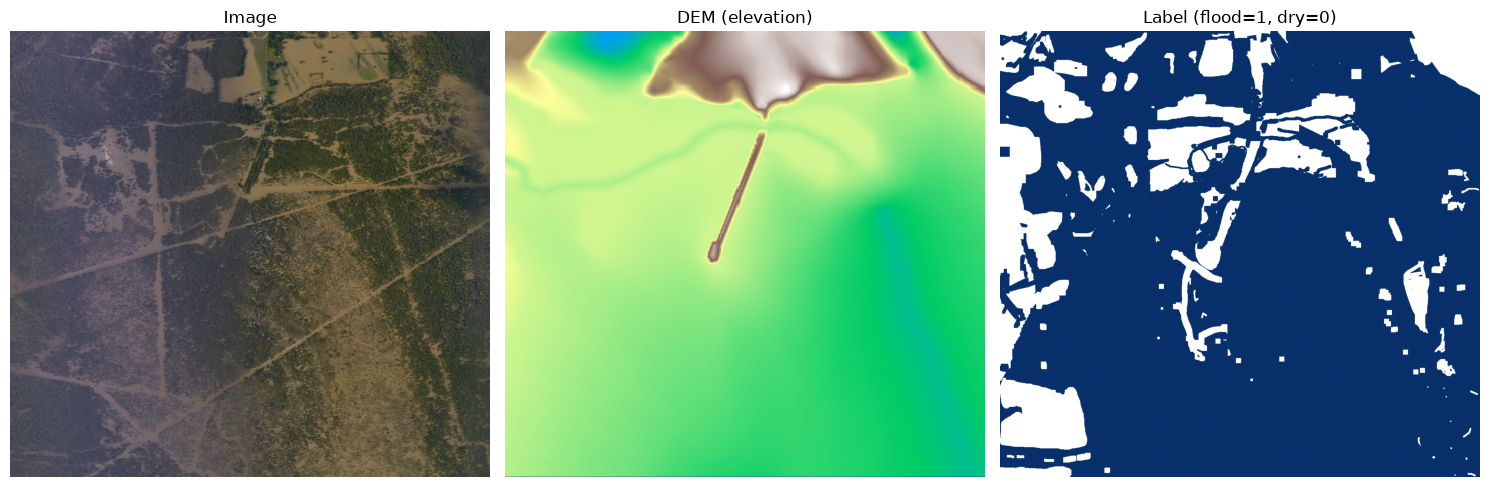

In [4]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt

scene = "data/image_6"

with rasterio.open(f"{scene}/image.tif") as src:
    image = src.read()  # (bands, H, W)
with rasterio.open(f"{scene}/dem.tif") as src:
    dem = src.read(1)
with rasterio.open(f"{scene}/label.tif") as src:
    label = src.read(1)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# If image has 3+ bands in RGB order, transpose to (H, W, C) for imshow.
# If it's a single band or a different band order, adjust this.
rgb = np.transpose(image[:3], (1, 2, 0))
rgb = rgb / max(rgb.max(), 1)  # quick-and-dirty normalization for display
axes[0].imshow(rgb)
axes[0].set_title("Image")

axes[1].imshow(dem, cmap="terrain")
axes[1].set_title("DEM (elevation)")

# label: 0=dry, 1=flood, 255=nodata -- mask nodata so it doesn't dominate the colormap
masked_label = np.ma.masked_equal(label, -1)
axes[2].imshow(masked_label, cmap="Blues", vmin=0, vmax=1)
axes[2].set_title("Label (flood=1, dry=0)")

for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.savefig("image_0_preview.png", dpi=150)
print("Saved image_0_preview.png")

3. Check the label's class balance

In [5]:
from pathlib import Path
import numpy as np
import rasterio

totals = {0: 0, 1: 0, -1: 0}
for label_path in sorted(Path("data").glob("image_*/label.tif")):
    with rasterio.open(label_path) as src:
        label = src.read(1)
        values, counts = np.unique(label, return_counts=True)
    c = dict(zip(values.tolist(), counts.tolist()))
    f, d = c.get(1, 0), c.get(0, 0)
    print(f"{label_path.parent.name}: {100 * f / (f + d):.1f}% flooded")
    for v, c in zip(values, counts):
        totals[int(v)] = totals.get(int(v), 0) + int(c)

dry, flood, nodata = totals[0], totals[1], totals[-1]
known = dry + flood
print(f"dry: {dry:,}, flood: {flood:,}, nodata: {nodata:,}")
print(f"% flooded (of known pixels): {100 * flood / known:.2f}%")

image_1: 74.8% flooded
image_10: 63.4% flooded
image_11: 85.6% flooded
image_12: 52.7% flooded
image_2: 96.9% flooded
image_3: 91.6% flooded
image_4: 97.0% flooded
image_5: 99.4% flooded
image_6: 100.0% flooded
image_7: 37.2% flooded
image_8: 11.2% flooded
image_9: 6.0% flooded
dry: 16,101,537, flood: 23,592,225, nodata: 16,924,530
% flooded (of known pixels): 59.44%


In [6]:
import rasterio
import numpy as np

#DEM's value range and units for each scene
for i in range(1, 13):
    scene = i

    with rasterio.open(f"data/image_{scene}/dem.tif") as src:
        dem = src.read(1, masked=True)  # respects nodata if set

    print(f" scene {scene}: min: {dem.min():.1f}  max: {dem.max():.1f}  mean: {dem.mean():.1f}")

 scene 1: min: 14.0  max: 33.2  mean: 26.9
 scene 2: min: 4.7  max: 10.7  mean: 7.8
 scene 3: min: 13.1  max: 29.7  mean: 22.8
 scene 4: min: -0.1  max: 8.5  mean: 2.6
 scene 5: min: -0.1  max: 17.7  mean: 4.2
 scene 6: min: 0.0  max: 6.7  mean: 2.7
 scene 7: min: 0.0  max: 15.4  mean: 7.8
 scene 8: min: -0.4  max: 14.1  mean: 5.5
 scene 9: min: -0.4  max: 15.1  mean: 6.2
 scene 10: min: 1.1  max: 13.4  mean: 6.4
 scene 11: min: 1.0  max: 12.9  mean: 5.8
 scene 12: min: 7.0  max: 29.5  mean: 18.8


#ONLY FOR ME TO USE MY NVIDIA GPU
%pip install torch torchvision --index-url https://download.pytorch.org/whl/cu128

In [7]:
import torch
print(torch.__version__, torch.cuda.is_available())

2.11.0+cu128 True


In [8]:
import torch.nn as nn

# ignore_index tells the loss to skip label==-1 entirely
criterion = nn.CrossEntropyLoss(ignore_index=-1)